# Buổi D5: Khi mô hình nói "70%", nó có đúng 70% không?

**Hiện trường.** Một mô hình dự đoán khách hàng **bỏ dịch vụ** và hiện cho mỗi khách một con số, ví dụ *"xác suất bỏ: 70%"*. Chị Hạnh dùng con số này để quyết định gọi điện giữ chân (tốn tiền) cho ai. Cô tự hỏi: **trong những khách mô hình báo khoảng 70%, có thật 70% bỏ đi không?** Nếu thực tế chỉ 40%, ngân sách giữ chân bị chọn sai.

Buổi này dạy bạn **kiểm tra độ đáng tin của xác suất** (hiệu chỉnh, *calibration*), đo bằng điểm Brier, sửa bằng `CalibratedClassifierCV`, và dùng xác suất để **quyết định theo chi phí**.

**Mindset của người làm dữ liệu:** xếp hạng đúng chưa đủ. Nếu con số được dùng như *xác suất thật* để ra quyết định, nó phải **trung thực**.

**Lưu ý:** dữ liệu được sinh ra bằng `make_classification` của sklearn (dựng có chủ đích, giả lập khách hàng), không phải dữ liệu thật.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: mô hình báo 70%, thực tế bao nhiêu? |
| Chặng 1 | Biểu đồ độ tin cậy: đọc thế nào |
| Chặng 2 | Đo bằng một con số: điểm Brier |
| Chặng 3 | Sửa: hiệu chỉnh bằng sigmoid hoặc isotonic |
| Chặng 4 | Dùng xác suất để quyết định theo chi phí |
| Chặng 5 | Hiệu chỉnh không đổi thứ hạng |

## Chặng 0: Thấy ngay, mô hình báo 70%, thực tế bao nhiêu?

**Câu hỏi:** những ca mô hình báo khoảng 70% có thật sự khoảng 70% bỏ đi?

Ta dựng bảng **6000 khách hàng giả lập** (20 chỉ số, khoảng 30% bỏ dịch vụ), chia ba phần: học, hiệu chỉnh (để dùng ở chặng 3), thi. Rồi huấn luyện **Naive Bayes** (đã học ở C4), mô hình nổi tiếng xếp hạng ổn nhưng xác suất thì "tự tin quá".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
X, y = make_classification(n_samples=6000, n_features=20, n_informative=6, n_redundant=6, weights=[0.7, 0.3], flip_y=0.05, class_sep=0.9, random_state=0)
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
X_train, X_cal, y_train, y_cal = train_test_split(X_rest, y_rest, test_size=0.3, random_state=0, stratify=y_rest)
nbm = GaussianNB().fit(X_train, y_train)
p_nb = nbm.predict_proba(X_test)[:, 1]
high = (p_nb >= 0.6) & (p_nb < 0.8)
print("churn share overall:", round(y_test.mean(), 3))
print("cases the model scores between 0.6 and 0.8:", int(high.sum()), "| mean score:", round(p_nb[high].mean(), 3), "| actually churned:", round(y_test[high].mean(), 3))

churn share overall: 0.312
cases the model scores between 0.6 and 0.8: 202 | mean score: 0.699 | actually churned: 0.396


**Giải thích từng dòng**

- `make_classification(...)`: máy sinh dữ liệu giả của sklearn. `weights=[0.7, 0.3]` đặt tỉ lệ hai nhóm; `n_informative=6` nghĩa là chỉ 6 cột thật sự mang tín hiệu; `flip_y=0.05` làm sai ngẫu nhiên 5% nhãn để dữ liệu có nhiễu giống đời thật.
- `train_test_split(...) hai lần`: chia ba phần: học (49%), hiệu chỉnh (21%), thi (30%). Phần hiệu chỉnh dành cho chặng 3.
- `GaussianNB().fit(...)`: Naive Bayes (C4).
- `nbm.predict_proba(X_test)[:, 1]`: xác suất bỏ dịch vụ mô hình đưa ra cho từng khách ở tập thi.
- `high = (p_nb >= 0.6) & (p_nb < 0.8)`: dãy đúng/sai: khách nào mô hình báo trong khoảng 60% đến 80%. `&` là 'và'.
- `y_test[high].mean()`: trong nhóm đó, tỉ lệ thật sự bỏ dịch vụ. Với nhãn 0 hoặc 1, trung bình là tỉ lệ nhãn 1.

**Cách đọc.**
- **Con số:** mô hình báo trung bình **70%** cho **202** khách, nhưng thực tế **39,6%** bỏ dịch vụ thật.
- **Bức tranh:** khi hai số lệch nhau, con số mô hình in ra **không phải xác suất thật** ở khoảng đó. Nếu chị Hạnh đọc nó như xác suất thật, cô sẽ tính sai hiệu quả của chiến dịch.
- **Câu hỏi tiếp:** cần một cách nhìn **toàn bộ** các mức, không chỉ mức 90%.

**Mang về chặng 0:** xác suất mô hình in ra chưa chắc là xác suất thật; phải kiểm tra.

## Chặng 1: Biểu đồ độ tin cậy

**Câu hỏi:** xác suất báo ở mọi mức có khớp với thực tế không?

Đời thường: dự báo thời tiết nói "mưa 30%". Nếu xét tất cả những ngày dự báo 30%, đúng khoảng **30% số ngày có mưa** thì dự báo **đáng tin** (đã hiệu chỉnh).

Cách vẽ: chia các ca thành nhóm theo xác suất báo (0 đến 0,1; 0,1 đến 0,2; ...), với mỗi nhóm lấy **xác suất báo trung bình** và **tỉ lệ thật**. Điểm nằm trên đường chéo là mô hình trung thực.

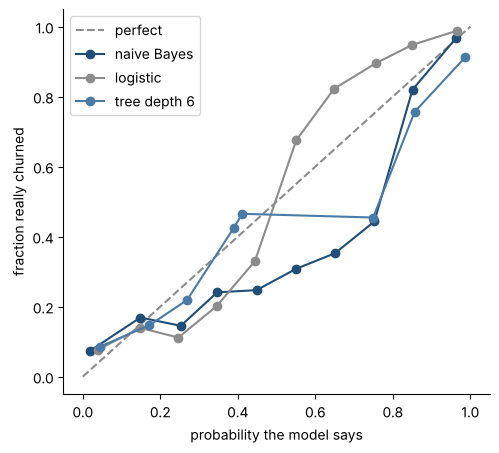

In [3]:
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
lr = LogisticRegression(max_iter=2000).fit(X_train, y_train)
tr = DecisionTreeClassifier(max_depth=6, random_state=0).fit(X_train, y_train)
probs = {"naive Bayes": p_nb, "logistic": lr.predict_proba(X_test)[:, 1], "tree depth 6": tr.predict_proba(X_test)[:, 1]}
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", label="perfect")
for (name, p), color in zip(probs.items(), [BLUE, GRAY, "#4A7BA7"]):
    frac, mean_p = calibration_curve(y_test, p, n_bins=10)
    ax.plot(mean_p, frac, marker="o", color=color, label=name)
ax.set_xlabel("probability the model says"); ax.set_ylabel("fraction really churned"); ax.legend()
plt.show()

**Giải thích từng dòng**

- `calibration_curve(y_test, p, n_bins=10)`: chia xác suất thành 10 nhóm; trả về hai dãy: tỉ lệ thật mỗi nhóm (`frac`) và xác suất báo trung bình mỗi nhóm (`mean_p`).
- `zip(probs.items(), [BLUE, GRAY, ...])`: ghép từng mô hình với một màu để vẽ.
- `ax.plot([0, 1], [0, 1], linestyle='--')`: đường chéo: nơi xác suất báo bằng tỉ lệ thật.

**Cách đọc.**
- **Con số:** đọc trục: x là điều mô hình nói, y là điều thực tế.
- **Bức tranh:** đường **dưới** đường chéo nghĩa là mô hình **nói quá** (báo cao hơn thực tế); đường **trên** là **nói thiếu**. Trong hình này không mô hình nào bám sát đường chéo: Naive Bayes nằm dưới ở khoảng giữa (nói quá), hồi quy logistic nằm trên ở khoảng 0,5 đến 0,9 (nói thiếu), cây thì thất thường. **Nói thật:** hướng lệch phụ thuộc cả mô hình lẫn dữ liệu; đừng đoán, hãy vẽ. Mỗi nhóm chỉ có vài trăm ca nên các điểm cũng dao động ngẫu nhiên.
- **Câu hỏi tiếp:** cần một con số duy nhất để so sánh.

**Mang về chặng 1:** biểu đồ độ tin cậy đặt xác suất báo cạnh tần suất thật; lệch khỏi đường chéo là xác suất không trung thực.

## Chặng 2: Một con số, điểm Brier

**Câu hỏi:** chấm xác suất bằng một con số thế nào?

Đời thường: bạn đoán mưa 90% mà trời nắng thì **phạt nặng**; đoán 10% mà trời nắng thì phạt nhẹ. **Điểm Brier** là trung bình của (xác suất báo - kết quả thật)², với kết quả thật là 0 hoặc 1. **Càng nhỏ càng tốt.** Đoán mò theo tỉ lệ chung cho điểm Brier cố định, ta dùng nó làm mốc.

In [4]:
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
base_rate = y_train.mean()
print("baseline (always say the base rate): Brier", round(brier_score_loss(y_test, np.full(len(y_test), base_rate)), 4))
rows = [{"model": n, "Brier": brier_score_loss(y_test, p), "log_loss": log_loss(y_test, p), "AUC": roc_auc_score(y_test, p)} for n, p in probs.items()]
score_before = pd.DataFrame(rows)
print(score_before.round(4).to_string(index=False))

baseline (always say the base rate): Brier 0.2147
       model  Brier  log_loss    AUC
 naive Bayes 0.1377    0.4584 0.8672
    logistic 0.1110    0.3815 0.8757
tree depth 6 0.1113    0.6532 0.8772


**Giải thích từng dòng**

- `brier_score_loss(y_test, p)`: điểm Brier: trung bình bình phương sai số của xác suất.
- `np.full(len(y_test), base_rate)`: mô hình 'mốc': luôn báo đúng tỉ lệ chung (khoảng 30%) cho mọi khách.
- `log_loss(y_test, p)`: thước đo khác, phạt **rất nặng** khi báo gần 0% mà sự việc lại xảy ra. Cũng là càng nhỏ càng tốt.
- `roc_auc_score(y_test, p)`: AUC chỉ đo **thứ hạng** (C2), không đo độ trung thực của con số.

**Cách đọc.**
- **Con số:** điểm Brier của Naive Bayes **0,138**, logistic **0,111**, cây **0,111**. AUC lần lượt **0,867**, **0,876**, **0,877**.
- **Bức tranh:** hai thước đo trả lời hai câu khác nhau: **AUC** hỏi "xếp khách nguy cơ cao lên trên đúng không?"; **Brier** hỏi "con số in ra có trung thực không?". Một mô hình có thể xếp tốt mà vẫn nói sai độ lớn.
- **Câu hỏi tiếp:** sửa con số mà không phá thứ hạng?

**Mang về chặng 2:** Brier và log loss chấm độ trung thực của xác suất; AUC chấm thứ hạng; cần cả hai.

## Chặng 3: Sửa bằng hiệu chỉnh

**Câu hỏi:** làm thế nào để con số trung thực hơn mà không đổi mô hình?

Đời thường: cái cân luôn đo nặng hơn 2 ký. Ta không vứt cân mà **đặt bảng quy đổi**: cân chỉ 62 thì thực là 60. **Hiệu chỉnh** (*calibration*) học bảng quy đổi từ **xác suất báo** sang **tần suất thật**, trên **dữ liệu mà mô hình chưa học**.

Hai kiểu: **sigmoid** (một đường cong chữ S có 2 tham số, ít dữ liệu cũng ổn) và **isotonic** (đường bậc thang tăng dần, linh hoạt nhưng cần nhiều dữ liệu).

In [5]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
cal_sig = CalibratedClassifierCV(FrozenEstimator(nbm), method="sigmoid").fit(X_cal, y_cal)
cal_iso = CalibratedClassifierCV(FrozenEstimator(nbm), method="isotonic").fit(X_cal, y_cal)
probs_after = {"naive Bayes (raw)": p_nb, "NB + sigmoid": cal_sig.predict_proba(X_test)[:, 1], "NB + isotonic": cal_iso.predict_proba(X_test)[:, 1]}
after = pd.DataFrame([{"model": n, "Brier": brier_score_loss(y_test, p), "log_loss": log_loss(y_test, p), "AUC": roc_auc_score(y_test, p)} for n, p in probs_after.items()])
print(after.round(4).to_string(index=False))

            model  Brier  log_loss    AUC
naive Bayes (raw) 0.1377    0.4584 0.8672
     NB + sigmoid 0.1285    0.4123 0.8672
    NB + isotonic 0.1218    0.3907 0.8648


**Giải thích từng dòng**

- `FrozenEstimator(nbm)`: 'đóng băng' mô hình đã học xong để hiệu chỉnh **không học lại nó**, chỉ học bảng quy đổi.
- `CalibratedClassifierCV(..., method='sigmoid')`: bọc mô hình lại, học bảng quy đổi bằng đường cong S. (Đã gặp ở C6 với `ensemble=False`; ở đây ta tự cấp phần dữ liệu hiệu chỉnh riêng.)
- `.fit(X_cal, y_cal)`: học bảng quy đổi trên **phần hiệu chỉnh**, tách khỏi phần học và phần thi.

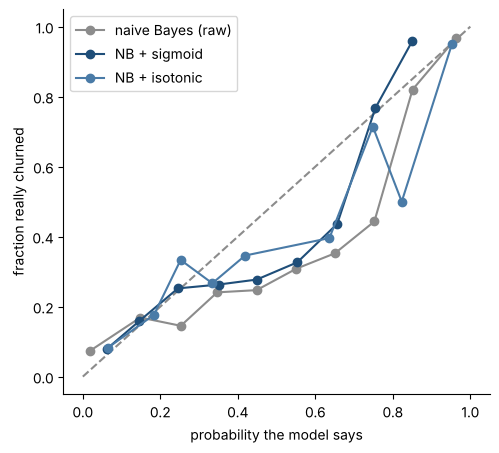

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--")
for (name, p), color in zip(probs_after.items(), [GRAY, BLUE, "#4A7BA7"]):
    frac, mean_p = calibration_curve(y_test, p, n_bins=10)
    ax.plot(mean_p, frac, marker="o", color=color, label=name)
ax.set_xlabel("probability the model says"); ax.set_ylabel("fraction really churned"); ax.legend()
plt.show()

**Giải thích từng dòng**

**Cách đọc.**
- **Con số:** Brier của Naive Bayes từ **0,138** xuống **0,129** (sigmoid) và **0,122** (isotonic). Log loss từ **0,458** xuống **0,412** và **0,391**.
- **Bức tranh:** đối chiếu hình mới với hình cũ: đường sau hiệu chỉnh nên **gần đường chéo hơn** ở phần giữa. Mức cải thiện của Brier là **vừa phải**, không phải thần kỳ, vì phần lớn lỗi nằm ở chính mô hình chứ không chỉ ở con số.
- **Quy tắc:** hiệu chỉnh trên **phần dữ liệu riêng** (không phải phần học, không phải phần thi). Dữ liệu ít (vài trăm ca) thì sigmoid; nhiều (hàng nghìn ca) thì isotonic cũng ổn.
- **Lưu ý:** hiệu chỉnh xong vẫn phải **kiểm tra lại trên tập thi**, như ta vừa làm.

**Mang về chặng 3:** hiệu chỉnh là học bảng quy đổi xác suất trên dữ liệu riêng; kiểm lại bằng Brier và biểu đồ độ tin cậy.

## Chặng 4: Dùng xác suất để quyết định theo chi phí

**Câu hỏi:** xác suất trung thực giúp gì cho quyết định?

Chị Hạnh có quy tắc kinh doanh: **gọi giữ chân** một khách tốn **50.000 đ**; nếu khách đó thật sự định bỏ và được giữ lại, công ty **tránh mất 400.000 đ** lợi nhuận. Giả sử gọi là giữ được hẳn khách sắp bỏ (đơn giản hóa dựng cho bài). Vậy:

- Gọi khách có xác suất bỏ `p` thì kỳ vọng lợi: `p × 400.000 − 50.000`. Dương khi `p > 50.000 / 400.000 = 12,5%`.
- Vậy **ngưỡng hợp lý là 12,5%**, rất xa 50% mặc định. Nhưng chỉ đúng nếu `p` **trung thực**.

Ta so tổng lợi nhuận trên tập thi khi dùng ngưỡng 12,5% với xác suất chưa và đã hiệu chỉnh.

In [7]:
cost_call, saving = 50_000, 400_000
threshold = cost_call / saving
def profit(p, t):
    call = p >= t
    return int(((call & (y_test == 1)).sum()) * saving - call.sum() * cost_call)
rows = [{"probabilities": n, "customers called": int((p >= threshold).sum()), "profit (VND)": profit(p, threshold)} for n, p in probs_after.items()]
print("threshold =", threshold)
print(pd.DataFrame(rows).to_string(index=False))
print("call nobody: 0 | call everybody:", profit(np.ones(len(y_test)), 0.5))

threshold = 0.125
    probabilities  customers called  profit (VND)
naive Bayes (raw)              1081     147950000
     NB + sigmoid               987     146250000
    NB + isotonic              1044     147800000
call nobody: 0 | call everybody: 134800000


**Giải thích từng dòng**

- `threshold = cost_call / saving`: ngưỡng hòa vốn: tiền gọi chia tiền cứu được = 0,125.
- `def profit(p, t):`: định nghĩa hàm tính tổng lợi nhuận khi gọi mọi khách có xác suất từ ngưỡng `t` trở lên.
- `call & (y_test == 1)`: vừa được gọi, vừa thật sự định bỏ: những ca cứu được. `&` là 'và'.
- `np.ones(len(y_test))`: mọi xác suất bằng 1: tức là gọi tất cả mọi người.
- `50_000`: dấu gạch dưới trong số chỉ để dễ đọc, không đổi giá trị.

In [8]:
for n, p in probs_after.items():
    call = p >= threshold
    forecast = int((p[call] * saving).sum() - call.sum() * cost_call)
    print(n, "| forecast profit:", f"{forecast:,}", "| actual:", f"{profit(p, threshold):,}")

naive Bayes (raw) | forecast profit: 201,545,250 | actual: 147,950,000
NB + sigmoid | forecast profit: 162,197,482 | actual: 146,250,000
NB + isotonic | forecast profit: 164,134,929 | actual: 147,800,000


**Giải thích từng dòng**

- `(p[call] * saving).sum()`: **lợi nhuận mô hình tự dự báo**: mỗi khách được gọi, kỳ vọng cứu được `p × 400.000`. Nếu `p` trung thực thì tổng dự báo gần tổng thực.
- `call.sum() * cost_call`: tổng tiền gọi.

**Cách đọc.**
- **Con số:** ngưỡng hòa vốn **12,5%**. Gọi theo xác suất thô của Naive Bayes: **1081** khách, lợi nhuận **147,950,000** đ; sau sigmoid: **987** khách, **146,250,000** đ; isotonic: **1044** khách, **147,800,000** đ. Gọi hết mọi người: **134,800,000** đ.
- **Bức tranh:** ba cách gần như **cho cùng lợi nhuận thật**, vì ngưỡng 12,5% thấp nên hầu hết khách có xác suất đáng kể đều bị gọi dù xác suất thô hay đã hiệu chỉnh. **Nói thật:** hiệu chỉnh ở đây không tăng tiền.
- **Cái hiệu chỉnh thật sự sửa:** **lời dự báo**. Ở bước ngay trên, so *lợi nhuận mô hình tự dự báo* với *lợi nhuận thật*: xác suất trung thực cho dự báo gần thực tế hơn xác suất thô. Dùng xác suất để **lập kế hoạch ngân sách hoặc báo cáo cho sếp** thì sai lệch này mới đắt.
- **Câu hỏi tiếp:** hiệu chỉnh có làm mô hình xếp hạng khác đi không?

**Mang về chặng 4:** ngưỡng ra quyết định = chi phí hành động ÷ lợi ích khi đúng; cần xác suất trung thực để ngưỡng đó có nghĩa.

## Chặng 5: Hiệu chỉnh không đổi thứ hạng (nhiều)

**Câu hỏi:** sửa con số có làm hỏng khả năng xếp hạng?

Hiệu chỉnh sigmoid là hàm **đơn điệu** (tăng đều), nên **thứ tự các ca không đổi**, AUC y nguyên. Isotonic cũng đơn điệu nhưng có thể làm nhiều ca **bằng nhau** (bậc thang), nên AUC có thể giảm nhẹ.

In [9]:
print(after[["model", "AUC"]].round(4).to_string(index=False))
same_order = np.array_equal(np.argsort(p_nb, kind="stable"), np.argsort(probs_after["NB + sigmoid"], kind="stable"))
print("sigmoid keeps the exact same order:", same_order)

            model    AUC
naive Bayes (raw) 0.8672
     NB + sigmoid 0.8672
    NB + isotonic 0.8648
sigmoid keeps the exact same order: True


**Giải thích từng dòng**

- `np.argsort(p, kind='stable')`: thứ tự các ca từ xác suất thấp đến cao; `stable` giữ nguyên thứ tự ban đầu khi bằng nhau.
- `np.array_equal(a, b)`: hai dãy giống hệt nhau không?

**Cách đọc.** AUC của Naive Bayes gốc **0,8672**, sau sigmoid **0,8672**, sau isotonic **0,8648**. Sigmoid giữ nguyên thứ tự: **True**.

**Phán quyết cho chị Hạnh:**
1. Nếu chỉ cần **xếp hạng** (ai gọi trước) thì không cần hiệu chỉnh.
2. Nếu dùng xác suất để **tính tiền, đặt ngưỡng, hoặc nói với người khác** ("khả năng bỏ là 70%") thì **phải hiệu chỉnh và kiểm tra**.
3. Báo cáo cả **AUC** (thứ hạng) lẫn **Brier** (độ trung thực).

**Bài học nghề:** nhiều mô hình mạnh (rừng, SVM, mạng nơ-ron, Naive Bayes) cho điểm xếp hạng giỏi nhưng xác suất lệch. Đừng đọc con số in ra là xác suất thật khi chưa kiểm tra.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Xác suất mô hình in ra chưa chắc là xác suất thật. |
| 1 | Biểu đồ độ tin cậy: trên đường chéo là trung thực; dưới là nói quá; trên là nói thiếu. |
| 2 | Brier và log loss chấm độ trung thực; AUC chấm thứ hạng. |
| 3 | Hiệu chỉnh bằng bảng quy đổi học trên dữ liệu riêng: sigmoid hoặc isotonic. |
| 4 | Ngưỡng quyết định = chi phí hành động ÷ lợi ích khi đúng, và cần xác suất trung thực. |
| 5 | Chỉ cần thứ hạng thì không cần hiệu chỉnh; dùng như xác suất thì phải. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Dự báo "mưa 30%" có đúng 30% không | độ hiệu chỉnh (calibration) | `calibration_curve` |
| Phạt nặng khi báo chắc chắn mà sai | điểm Brier / log loss | `brier_score_loss`, `log_loss` |
| Bảng quy đổi cái cân lệch 2 ký | hiệu chỉnh xác suất | `CalibratedClassifierCV` |
| Đường cong chữ S | hiệu chỉnh sigmoid | `method="sigmoid"` |
| Đường bậc thang tăng dần | hiệu chỉnh isotonic | `method="isotonic"` |
| Đóng băng mô hình, chỉ học bảng quy đổi | mô hình đóng băng | `FrozenEstimator` |
| Tiền gọi ÷ tiền cứu được | ngưỡng hòa vốn | `cost_call / saving` |

**Thử thách tự làm**

1. Thay Naive Bayes bằng `SVC(probability=False)` kèm `CalibratedClassifierCV(SVC(), ensemble=False)` (như C6). Brier thay đổi ra sao so với Naive Bayes đã hiệu chỉnh?
2. Đổi chi phí gọi thành 150.000 đ. Ngưỡng hòa vốn mới là bao nhiêu và số khách được gọi thay đổi thế nào?
3. Giảm phần hiệu chỉnh xuống còn 200 ca. Sigmoid hay isotonic ổn hơn? Vì sao?
4. Vẽ biểu đồ độ tin cậy của `DecisionTreeClassifier(max_depth=3)` và `max_depth=12`. Cây nào nói thật hơn?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Vẽ và đọc được biểu đồ độ tin cậy.
- [ ] Phân biệt Brier (trung thực) và AUC (thứ hạng).
- [ ] Hiệu chỉnh một mô hình trên phần dữ liệu riêng và kiểm lại.
- [ ] Tính ngưỡng quyết định từ chi phí và lợi ích.
- [ ] Nói được khi nào không cần hiệu chỉnh.

## Phần thưởng (Tip pro): Hiệu chỉnh khi cũng phải chọn ngưỡng cho nhiều nhóm


Với bài toán **nhiều nhóm** (như chữ số 0 đến 9), hiệu chỉnh làm theo kiểu "một nhóm so với phần còn lại" rồi chuẩn hóa để tổng bằng 1; `CalibratedClassifierCV` làm tự động. Với dữ liệu thay đổi theo thời gian, bảng quy đổi cũng **cũ đi**: kiểm tra biểu đồ độ tin cậy định kỳ trên dữ liệu mới, vì khách hàng hôm nay không giống khách hàng năm ngoái.